# 01 — Data exploration: 2023 Bahrain Grand Prix

**Goal of this notebook:** load one race, clean the laps so that only *representative racing laps* remain, and check that the data shows what the lap-time model will need to learn — especially **tyre degradation**.

**Why Bahrain 2023?** Dry race, high tyre degradation (abrasive surface), most drivers made **two stops**, and only one short Virtual Safety Car. That makes it a good first case for a strategy model.

**Data source:** [OpenF1](https://openf1.org), a free public API (no key). FastF1 was the original plan, but its current version requires a paid F1TV subscription to download timing data, which this project avoids on purpose.

*Unofficial project. Not affiliated with Formula 1, the FIA or any team.*

In [1]:
# Parameters
YEAR = 2023
COUNTRY = "Bahrain"
DRIVERS_TO_PLOT = ["VER", "PER", "ALO", "HAM"]

In [2]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Run from the project root so relative paths (data/cache, reports/figures) work.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

from src.data_loader import load_clean_race, neutralised_periods, load_raw_race, save_processed

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# One fixed colour per compound (validated for colour-blind safety).
COMPOUND_COLORS = {"SOFT": "#eb6834", "MEDIUM": "#1baf7a", "HARD": "#2a78d6"}
COMPOUND_ORDER = ["SOFT", "MEDIUM", "HARD"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
})

## 1. Load and clean

`load_clean_race` downloads six OpenF1 tables (laps, stints, race control, weather, drivers, position), cached in `data/cache/`, and joins them into **one row per driver per lap**:

- **Tyres:** each lap is matched to its stint → `Compound`, `Stint`, `TyreLife` (laps on that set, counting laps used in qualifying).
- **Weather:** latest sample *before* the lap started (`merge_asof` backward → no look-ahead).
- **Position:** latest classified position before the lap started.
- **Neutralised:** a lap is flagged if it overlaps a SC / VSC / red-flag window built from race-control messages.

Then `clean_laps` removes laps that do not represent normal racing pace. Each lap is counted under the **first** rule that removes it:

In [3]:
all_laps, laps, removal_report = load_clean_race(YEAR, COUNTRY)
removal_report

,rule,laps_removed
0,no lap time,3
1,lap 1 (standing start),20
2,pit in-lap,50
3,pit out-lap,50
4,SC / VSC / red flag,19
5,inaccurate timing,4
6,unknown compound,0
7,outlier (> 107% of driver median),1
8,TOTAL removed,147
9,kept,911


**Why each rule:**

| Rule | Reason |
|---|---|
| no lap time | nothing to learn from |
| lap 1 | standing start: the car accelerates from zero and the field is bunched |
| pit in-lap / out-lap | include pit-lane time — they are the *pit loss*, which the simulator adds separately |
| SC / VSC / red flag | everyone drives slowly on purpose; not related to tyres or fuel |
| inaccurate timing | OpenF1 has no `IsAccurate` flag, so we keep only laps whose three sectors exist and add up to the lap time |
| outlier (> 107 %) | laps much slower than the driver's own median: failures, spins, damage (e.g. Piastri's last lap before retiring). The 107 % idea mirrors the F1 qualifying rule; it is applied **per driver**, so slower cars are not penalised |

About 14 % of laps are removed; most of that is pit laps (2 per stop) and lap 1.

In [4]:
periods = neutralised_periods(load_raw_race(YEAR, COUNTRY)["race_control"])
print("Neutralised periods:")
print(periods.to_string(index=False))
print(f"\nLaps before cleaning: {len(all_laps)}  |  after: {len(laps)}  |  drivers: {laps['Driver'].nunique()}")

Neutralised periods:
status                     start                       end
   VSC 2023-03-05 16:10:19+00:00 2023-03-05 16:11:55+00:00

Laps before cleaning: 1058  |  after: 911  |  drivers: 20


## 2. The clean dataset

In [5]:
laps.head()

,Driver,DriverNumber,Team,LapNumber,LapStartDate,LapTime,Compound,TyreLife,Stint,Position,IsPitInLap,IsPitOutLap,IsNeutralised,IsAccurate,TrackTemp,AirTemp,Rainfall,Humidity
0,VER,1,Red Bull Racing,2,2023-03-05 15:05:17.858000+00:00,97.974,SOFT,5.0,1.0,1,False,False,False,True,31.2,27.3,0,22.0
1,VER,1,Red Bull Racing,3,2023-03-05 15:06:55.793000+00:00,98.006,SOFT,6.0,1.0,1,False,False,False,True,31.1,27.3,0,22.0
2,VER,1,Red Bull Racing,4,2023-03-05 15:08:33.885000+00:00,97.976,SOFT,7.0,1.0,1,False,False,False,True,31.2,27.3,0,22.0
3,VER,1,Red Bull Racing,5,2023-03-05 15:10:11.852000+00:00,98.035,SOFT,8.0,1.0,1,False,False,False,True,31.1,27.2,0,22.0
4,VER,1,Red Bull Racing,6,2023-03-05 15:11:49.866000+00:00,97.986,SOFT,9.0,1.0,1,False,False,False,True,31.0,27.2,0,22.0


In [6]:
laps[["LapTime", "TyreLife", "LapNumber", "Position", "TrackTemp", "AirTemp", "Rainfall"]].describe().round(2)

,LapTime,TyreLife,LapNumber,Position,TrackTemp,AirTemp,Rainfall
count,911.00,911.00,911.00,911.00,911.00,911.00,911.0
mean,98.59,10.16,28.44,9.84,29.91,26.75,0.0
std,1.32,5.76,16.38,5.45,0.75,0.32,0.0
min,94.00,2.00,2.00,1.00,28.70,26.20,0.0
25%,97.66,6.00,14.50,5.00,29.30,26.40,0.0
50%,98.35,9.00,28.00,10.00,29.90,26.70,0.0
75%,99.43,14.00,43.00,15.00,30.50,27.10,0.0
max,102.68,29.00,57.00,20.00,31.20,27.30,0.0


In [7]:
print("Laps per compound:")
print(laps["Compound"].value_counts())
print("\nRainfall values:", laps["Rainfall"].unique())

Laps per compound:
Compound
HARD      511
SOFT      392
MEDIUM      8
Name: count, dtype: int64

Rainfall values: [0]


**Two things to keep in mind for the model:**

- **MEDIUM is almost absent** (only a handful of laps). Almost everyone ran SOFT–SOFT–HARD or SOFT–HARD–HARD. A model trained on this race alone **cannot learn medium-tyre behaviour reliably** — a reason to add more races later.
- **No rain** (`Rainfall` is always 0) and track temperature only falls a few degrees, so weather features will carry little signal *in this race*.

## 3. Lap-time distribution

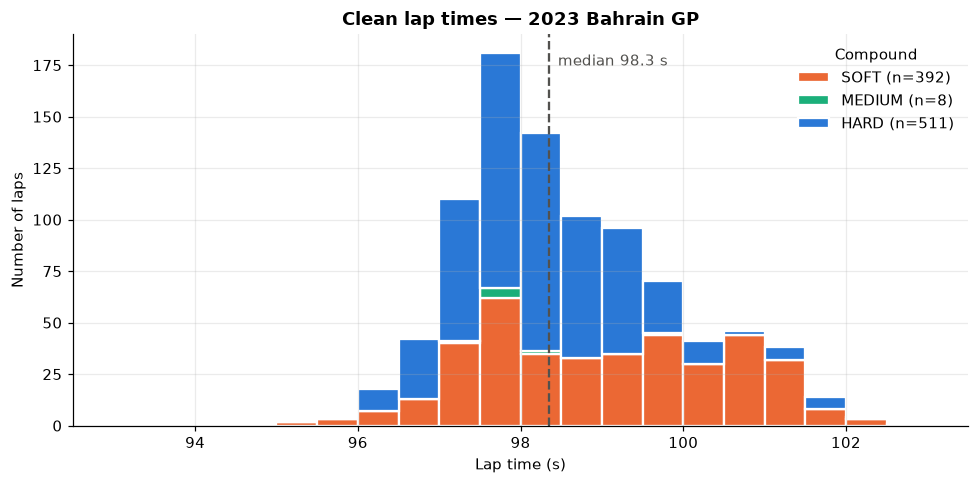

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.arange(np.floor(laps["LapTime"].min()), np.ceil(laps["LapTime"].max()) + 0.5, 0.5)
present = [c for c in COMPOUND_ORDER if (laps["Compound"] == c).any()]
ax.hist([laps.loc[laps["Compound"] == c, "LapTime"] for c in present], bins=bins, stacked=True,
        color=[COMPOUND_COLORS[c] for c in present], edgecolor="white", linewidth=1.5,
        label=[f"{c} (n={(laps['Compound'] == c).sum()})" for c in present])
ax.axvline(laps["LapTime"].median(), color="#52514e", linestyle="--", linewidth=1.5)
ax.annotate(f"median {laps['LapTime'].median():.1f} s", xy=(laps["LapTime"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color="#52514e")
ax.set_title(f"Clean lap times — {YEAR} {COUNTRY} GP")
ax.set_xlabel("Lap time (s)")
ax.set_ylabel("Number of laps")
ax.legend(title="Compound", frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_lap_time_distribution.png", bbox_inches="tight")
plt.show()

Most laps sit in a narrow ~5 s window. The spread comes from car performance (team), tyre age, fuel load and traffic — exactly what the model has to separate. The distribution is slightly right-skewed (mean above median): there is a hard limit on how fast a car can go, but many ways to be slow. SOFT laps sit on the slow side because they were run early, with a full fuel tank.

## 4. Race view: lap time per lap

Each panel is one driver; gaps are removed laps (pit stops, lap 1, VSC around lap 41). Two patterns compete:

- **Tyre wear** makes laps slower as the stint goes on (clear in ALO's and HAM's first stint on SOFT), and a fresh set brings the time down again after the stop.
- **Fuel burn** makes the whole race trend faster: the HARD stints at the end are the quickest laps of the race even on worn tyres. Drivers also manage pace (VER's second stint barely degrades — he was leading comfortably).

The model has to untangle these effects; this is why both `TyreLife` and `LapNumber` will be features.

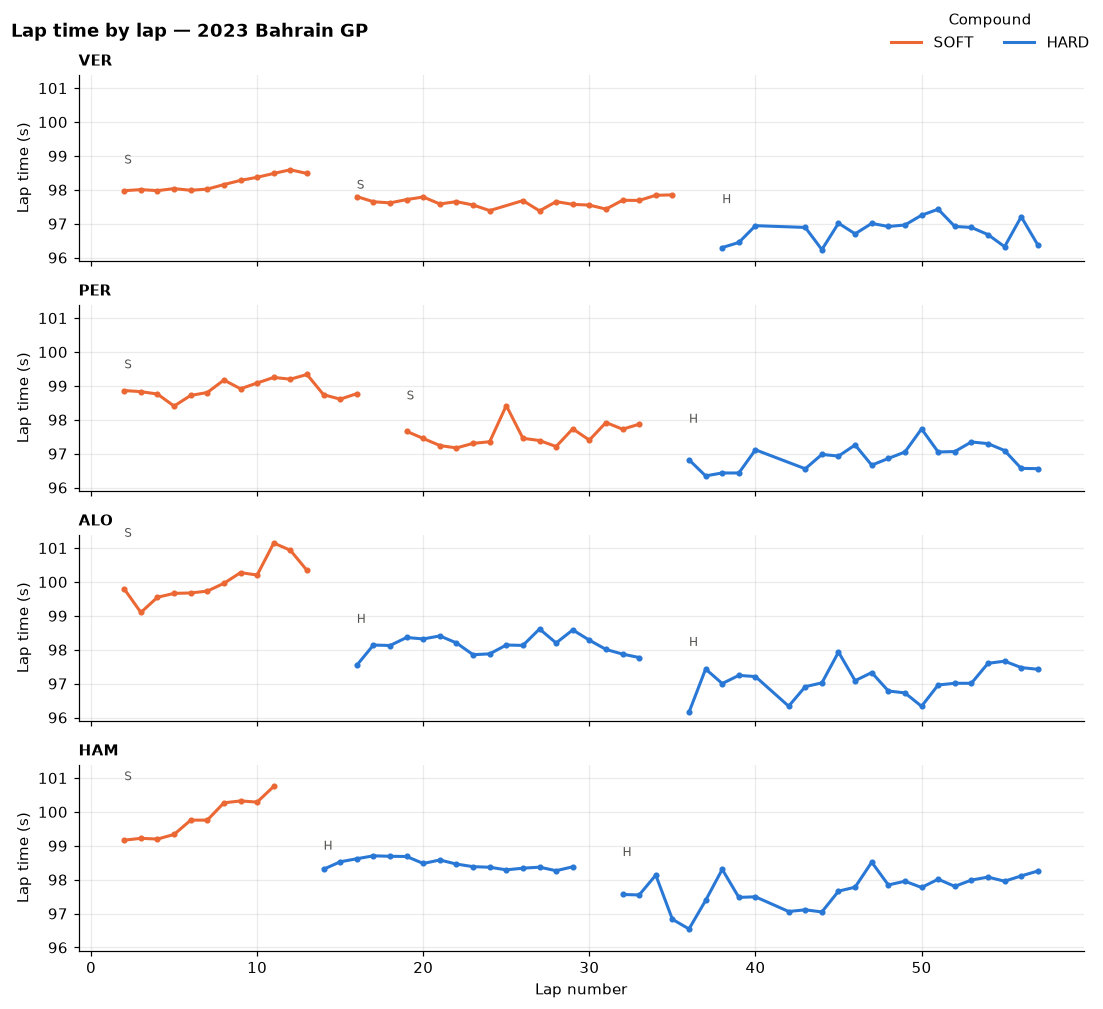

In [9]:
fig, axes = plt.subplots(len(DRIVERS_TO_PLOT), 1, figsize=(10, 2.3 * len(DRIVERS_TO_PLOT)),
                         sharex=True, sharey=True)
for ax, driver in zip(axes, DRIVERS_TO_PLOT):
    d = laps[laps["Driver"] == driver]
    for (stint, compound), s in d.groupby(["Stint", "Compound"]):
        ax.plot(s["LapNumber"], s["LapTime"], color=COMPOUND_COLORS[compound], linewidth=2,
                marker="o", markersize=3)
        ax.annotate(compound[0], xy=(s["LapNumber"].iloc[0], s["LapTime"].max()),
                    xytext=(0, 4), textcoords="offset points", fontsize=8, color="#52514e")
    ax.set_title(driver, loc="left", fontsize=10)
    ax.set_ylabel("Lap time (s)")
axes[-1].set_xlabel("Lap number")
used = set(laps.loc[laps["Driver"].isin(DRIVERS_TO_PLOT), "Compound"])
handles = [plt.Line2D([], [], color=COMPOUND_COLORS[c], linewidth=2, label=c)
           for c in COMPOUND_ORDER if c in used]
fig.legend(handles=handles, title="Compound", loc="upper right", frameon=False, ncol=3)
fig.suptitle(f"Lap time by lap — {YEAR} {COUNTRY} GP", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_race_lap_times.png", bbox_inches="tight")
plt.show()

## 5. Tyre degradation

To isolate the tyre effect from car speed, each lap is compared with **the same driver in the same stint**: `delta = lap time − mean of that stint's first 3 clean laps`. Then we take the median delta across all drivers for each lap into the stint.

> **Fuel confounder:** the car burns ~1.5–2 kg of fuel per lap and gets faster (roughly a few hundredths of a second per lap). Within a stint, tyre age and fuel load rise together, so the curve below shows **tyre wear minus fuel gain**. The real tyre degradation is *larger* than what we see. The model in Stage 2 will separate the two by using both `TyreLife` and `LapNumber`.

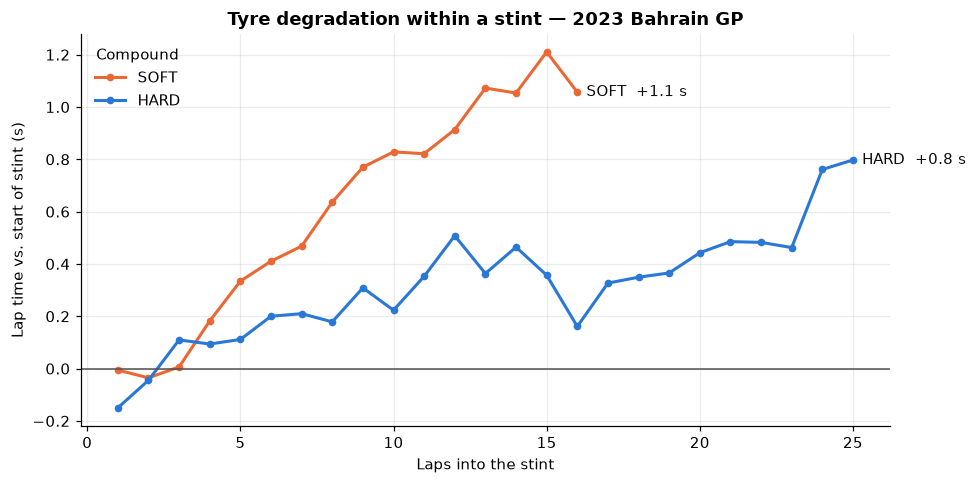

In [10]:
MIN_DRIVERS = 3  # only plot points backed by at least this many stints

stints = laps.sort_values("LapNumber").copy()
stints["LapInStint"] = stints.groupby(["Driver", "Stint"]).cumcount() + 1
reference = (stints[stints["LapInStint"] <= 3]
             .groupby(["Driver", "Stint"])["LapTime"].mean().rename("StintRef"))
stints = stints.join(reference, on=["Driver", "Stint"])
stints["Delta"] = stints["LapTime"] - stints["StintRef"]

curve = (stints.groupby(["Compound", "LapInStint"])["Delta"]
         .agg(["median", "count"]).reset_index())
curve = curve[curve["count"] >= MIN_DRIVERS]

fig, ax = plt.subplots(figsize=(9, 4.5))
for compound in COMPOUND_ORDER:
    c = curve[curve["Compound"] == compound]
    if c.empty:
        continue
    ax.plot(c["LapInStint"], c["median"], color=COMPOUND_COLORS[compound], linewidth=2,
            marker="o", markersize=4, label=compound)
    last = c.iloc[-1]
    ax.annotate(f"{compound}  +{last['median']:.1f} s", xy=(last["LapInStint"], last["median"]),
                xytext=(6, 0), textcoords="offset points", va="center", color="#0b0b0b")
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_title(f"Tyre degradation within a stint — {YEAR} {COUNTRY} GP")
ax.set_xlabel("Laps into the stint")
ax.set_ylabel("Lap time vs. start of stint (s)")
ax.legend(title="Compound", frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_tyre_degradation.png", bbox_inches="tight")
plt.show()

In [11]:
# Average degradation rate per compound: slope of a straight line through each stint, then the median.
def stint_slope(group: pd.DataFrame) -> float:
    return np.polyfit(group["LapInStint"], group["LapTime"], 1)[0] if len(group) >= 5 else np.nan

slopes = (stints.groupby(["Compound", "Driver", "Stint"]).apply(stint_slope, include_groups=False)
          .dropna().rename("s_per_lap").reset_index())
slopes.groupby("Compound")["s_per_lap"].agg(["median", "count"]).round(3).rename(
    columns={"median": "median slope (s/lap)", "count": "stints"})

,median slope (s/lap),stints
Compound,,
HARD,0.035,32
MEDIUM,0.235,1
SOFT,0.099,33


The plot and the table show the effect the model has to learn: **lap times rise steadily with tyre age**, and the SOFT degrades roughly 3× faster than the HARD (~0.10 vs ~0.035 s per lap, net of the fuel gain). The MEDIUM number comes from a single stint and should not be trusted. In Bahrain this is what pushes teams to stop twice: a long stint on worn softs costs more time than an extra ~20 s pit stop.

## 6. Track conditions

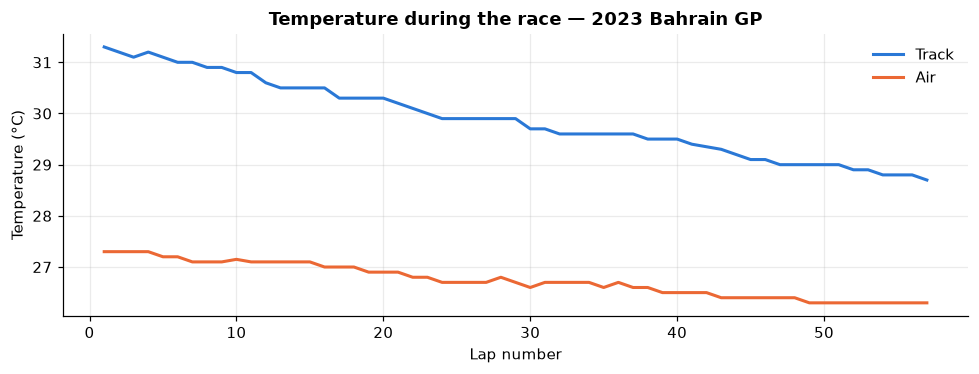

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.5))
temps = all_laps.groupby("LapNumber")[["TrackTemp", "AirTemp"]].median()
ax.plot(temps.index, temps["TrackTemp"], color="#2a78d6", linewidth=2, label="Track")
ax.plot(temps.index, temps["AirTemp"], color="#eb6834", linewidth=2, label="Air")
ax.set_title(f"Temperature during the race — {YEAR} {COUNTRY} GP")
ax.set_xlabel("Lap number")
ax.set_ylabel("Temperature (°C)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

The race started at dusk and ended at night, so the track cools by a few degrees. A cooler track tends to make cars slightly faster, which — like fuel — partly hides tyre wear in the second half of the race. Temperature and lap number are strongly correlated here, so the model will struggle to tell them apart with a single race.

## 7. Save the clean dataset

In [13]:
path = save_processed(laps, YEAR, COUNTRY)
print(f"Saved {len(laps)} laps to {path}")

Saved 911 laps to data\processed\laps_2023_bahrain.parquet


## Summary

- One row per driver per lap, with compound, tyre age, stint, position and weather.
- Removed laps that are not normal racing pace (lap 1, pit laps, VSC, inaccurate timing, outliers); the count per rule is in the table at the top.
- **Tyre degradation is clearly visible**, and stronger on SOFT than on HARD.
- **Limitations found already:** almost no MEDIUM laps, no rain, and fuel / track temperature / tyre age move together within one race. These are reasons to validate on more races later.

Next (Stage 2): build features and train a lap-time model, compared against a simple baseline.